# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import plotly.express as px

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

In [2]:
# Your code here
df = pd.read_csv("data/eda.csv", parse_dates=["date"])
df.head(5)

,date,price,house_id,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.0,7129300520,1,3.0,1.00,1180.0,5650.0,1.0,NaN,...,7,1180.0,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0
1,2014-12-09,538000.0,6414100192,2,3.0,2.25,2570.0,7242.0,2.0,0.0,...,7,2170.0,400.0,1951,1991.0,98125,47.7210,-122.319,1690.0,7639.0
2,2015-02-25,180000.0,5631500400,3,2.0,1.00,770.0,10000.0,1.0,0.0,...,6,770.0,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0
3,2014-12-09,604000.0,2487200875,4,4.0,3.00,1960.0,5000.0,1.0,0.0,...,7,1050.0,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0
4,2015-02-18,510000.0,1954400510,5,3.0,2.00,1680.0,8080.0,1.0,0.0,...,8,1680.0,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           21597 non-null  datetime64[us]
 1   price          21597 non-null  float64       
 2   house_id       21597 non-null  int64         
 3   id             21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

## EDA Analysis

** From file 03_eda_king_county_project.ipynb

The metric : RMSE is the primary metric; lower is better

> Use log on target variable - important! 

### Drop columns 
> drop sqft_living since it is the result of sqft_above + sqft_basement and we would have multicollinearity if keeping it plus redundant information

### Format data correctly
> date format -> date 
> zipcode should be a string
> house_id should be a string 
> id should be a string 

### Impute Missings 
>waterfront 
>view 
>sqft_basement has quite a few missings, maybe those dont have any basement? but theres also 0 values..

### Ordinal 
> waterfront should be a bool - also has quite a few missings -> onehotencode this as a feature
> view is the quality of view, so we need to make this an ordinal feature later on - also has missings
> condition is also supposed to be ordinal, scale from 1-5 
> probably the same for grade, ordinal too

### Create new features by hand 
>yr_renovated definitely needs to be a int instead of a float
yr_built and yr_renovated are intesting columns but maybe the age of the house and the years since last renovation would be the more interesting features
-> should probably create those from scratch and then drop the columns yr_built and yr_renovated
and then we'll see whether keeping those as a numeric feature or binning them is the better choice
I would make this choice depending on the range of values we get. 

>date (date sold) maybe split this feature into year sold, month sold, probably dont need the date day 

### Keep features with a high correlation with target variable 
> Probably at least these:
> sqft_living      0.701778
> grade            0.670040
> sqft_above       0.603072
> sqft_living15    0.588622
> bathrooms        0.529378
> view             0.400145
> sqft_basement    0.330814
> bedrooms         0.315422
> lat              0.305863
> waterfront       0.275487
> floors           0.258561 

In [4]:
df_train, df_test = train_test_split(
	df,
	test_size=0.25,
	random_state=42
)

print("Training shape:", df_train.shape)
print("Test shape:", df_test.shape)

Training shape: (16197, 22)
Test shape: (5400, 22)


# Feature engineering

- sale_year and sale_month from the sale date.
- house_age_at_sale from the sale year and construction year.
- years_since_renovation and ever_renovated from the renovation year.
- Categorical versions of zipcode and waterfront

In [5]:
def engineer_features(frame):
	out = frame.copy()

	# Extract information from the sale date
	dates = pd.to_datetime(out["date"], errors="coerce")
	out["sale_year"] = dates.dt.year
	out["sale_month"] = dates.dt.month
	out = out.drop(columns=["date"])

	# Age of the house at the time of sale
	out["house_age_at_sale"] = (
		out["sale_year"] - out["yr_built"]
	)

	# Renovation features: 0 means never renovated
	renovated = out["yr_renovated"].where(
		out["yr_renovated"] > 0, np.nan
	)

	out["ever_renovated"] = renovated.notna().astype(int)

	out["years_since_renovation"] = (
		out["sale_year"] - renovated
	)

	# Remove original year features and redundant living area
	out = out.drop(
		columns=[
			"yr_built",
			"yr_renovated",
			"sqft_living",
			"id",
			"house_id"
		],
		errors="ignore"
	)

	# ZIP codes are categories, not continuous measurements
	if "zipcode" in out.columns:
		out["zipcode"] = out["zipcode"].astype(object)

	if "waterfront" in out.columns:
		out["waterfront"] = out["waterfront"].astype(object)

	return out

# Transform training data only for now
train_fe = engineer_features(df_train)

display(train_fe.head())
print(train_fe.shape)

,price,bedrooms,bathrooms,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,...,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age_at_sale,ever_renovated,years_since_renovation
6405,529000.0,3.0,2.50,4499.0,2.0,0.0,0.0,3,8,1880.0,...,98029,47.5664,-121.999,2130.0,5114.0,2015,3,22,0,NaN
937,253000.0,3.0,2.50,6564.0,1.0,0.0,0.0,3,7,1310.0,...,98042,47.3545,-122.158,1710.0,5151.0,2014,10,20,0,NaN
19076,745000.0,5.0,4.00,493534.0,2.0,0.0,0.0,5,9,3960.0,...,98027,47.4536,-122.009,2160.0,219542.0,2015,1,40,0,NaN
15201,545000.0,2.0,2.00,3880.0,1.0,0.0,0.0,4,7,1430.0,...,98117,47.6844,-122.392,1430.0,3880.0,2015,3,66,0,NaN
13083,390000.0,3.0,2.25,32112.0,1.0,0.0,0.0,4,8,1740.0,...,98042,47.3451,-122.094,2310.0,41606.0,2014,10,34,0,NaN


(16197, 21)


# Separate features and target

In [6]:
X_train = train_fe.drop(columns="price")
y_train = df_train["price"].astype(float)

# Models will learn on the log-transformed target
y_train_log = np.log1p(y_train)

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['bedrooms', 'bathrooms', 'sqft_lot', 'floors', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age_at_sale', 'ever_renovated', 'years_since_renovation']
Categorical features: ['waterfront', 'zipcode']


# Build the two baselines
Both baselines predict prices in dollars. This makes their results directly comparable to the final dollar-scale evaluation of the regression models

In [7]:
# Mean baseline
mean_baseline = DummyRegressor(strategy="mean")

mean_baseline.fit(
    np.zeros((len(X_train), 1)),
    y_train
)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[541284.46]]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,1
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [8]:
# Rule-based baseline
numeric_for_rule = X_train.select_dtypes(
    include=np.number
)

rule_corr = numeric_for_rule.corrwith(y_train).abs()
rule_corr = rule_corr.dropna().sort_values(ascending=False)

rule_feature = rule_corr.index[0]

print("Rule feature:", rule_feature)
print("Absolute correlation:", rule_corr.iloc[0])

Rule feature: grade
Absolute correlation: 0.6717016226030638


In [9]:
rule_x = numeric_for_rule[rule_feature]
rule_x_mean = rule_x.mean()
rule_y_mean = y_train.mean()

rule_slope = (
    ((rule_x - rule_x_mean) * (y_train - rule_y_mean)).sum()
    / ((rule_x - rule_x_mean) ** 2).sum()
)

rule_intercept = rule_y_mean - rule_slope * rule_x_mean

print(
    f"Predicted price = {rule_intercept:.2f} "
    f"+ {rule_slope:.2f} * {rule_feature}"
)

Predicted price = -1070489.77 + 210450.05 * grade


# Build the preprocessing pipeline
Numeric columns will be imputed with their median and standardized. Categorical columns will be imputed with their most frequent value and one-hot encoded.

In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Tune Ridge on the original features
1- we perform a randomized search across a broad range of regularization strengths, alpha.

In [11]:
ridge_random_search = RandomizedSearchCV(
    estimator=ridge_pipeline,
    param_distributions={
        "model__alpha": loguniform(1e-3, 1e4)
    },
    n_iter=25,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

ridge_random_search.fit(X_train, y_train_log)

ridge_random_best = ridge_random_search.best_estimator_

print("Best parameters:", ridge_random_search.best_params_)
print("Best CV RMSE (log-price):", -ridge_random_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters: {'model__alpha': np.float64(0.0013934502251337594)}
Best CV RMSE (log-price): 0.18435273083746123


2- we perform a narrower grid search around the best value found

In [12]:
best_alpha = ridge_random_search.best_params_["model__alpha"]

grid_alphas = sorted(set(
    best_alpha * factor
    for factor in [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]
))

ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": grid_alphas},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

ridge_grid_search.fit(X_train, y_train_log)

ridge_grid_best = ridge_grid_search.best_estimator_

print("Best grid parameters:", ridge_grid_search.best_params_)
print("Best grid CV RMSE (log-price):", -ridge_grid_search.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best grid parameters: {'model__alpha': np.float64(0.0013934502251337594)}
Best grid CV RMSE (log-price): 0.18435273083746123


# Tune a second model using polynomial features

In [13]:
poly_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

poly_preprocessor = ColumnTransformer([
    ("num", poly_numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

poly_ridge_pipeline = Pipeline([
    ("preprocessor", poly_preprocessor),
    ("model", Ridge())
])

poly_random_search = RandomizedSearchCV(
    estimator=poly_ridge_pipeline,
    param_distributions={
        "model__alpha": loguniform(1e-2, 1e5)
    },
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

poly_random_search.fit(X_train, y_train_log)

poly_ridge_best = poly_random_search.best_estimator_

print("Best parameters:", poly_random_search.best_params_)
print("Best CV RMSE (log-price):", -poly_random_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters: {'model__alpha': np.float64(0.013934502251337596)}
Best CV RMSE (log-price): 0.1784402759547303


# Compare cross-validation results

In [14]:
cv_results = pd.DataFrame([
    {
        "Model": "Ridge randomized",
        "CV RMSE (log-price)": -ridge_random_search.best_score_
    },
    {
        "Model": "Ridge grid",
        "CV RMSE (log-price)": -ridge_grid_search.best_score_
    },
    {
        "Model": "Polynomial Ridge",
        "CV RMSE (log-price)": -poly_random_search.best_score_
    }
]).sort_values("CV RMSE (log-price)")

display(cv_results)

,Model,CV RMSE (log-price)
2,Polynomial Ridge,0.178440
0,Ridge randomized,0.184353
1,Ridge grid,0.184353


Select best model

In [15]:
model_candidates = {
    "Ridge randomized": ridge_random_best,
    "Ridge grid": ridge_grid_best,
    "Polynomial Ridge": poly_ridge_best
}

best_model_name = cv_results.iloc[0]["Model"]
best_model = model_candidates[best_model_name]

print("Selected model:", best_model_name)

Selected model: Polynomial Ridge


# Final evaluation on the test set

In [16]:
test_fe = engineer_features(df_test)

X_test = test_fe.drop(columns="price")
X_test = X_test.reindex(columns=X_train.columns)

y_test = df_test["price"].astype(float)

In [17]:
# Helper functions

def predict_dollars(model, X):
    predictions_log = model.predict(X)

    # Convert log1p predictions back to dollars
    predictions = np.expm1(predictions_log)

    # House prices cannot be negative
    return np.maximum(predictions, 0)


def calculate_metrics(y_true, y_pred):
    return {
        "RMSE ($)": root_mean_squared_error(y_true, y_pred),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    }

In [18]:
# Generate predictions for the mean baseline

mean_train_pred = mean_baseline.predict(
    np.zeros((len(X_train), 1))
)

mean_test_pred = mean_baseline.predict(
    np.zeros((len(X_test), 1))
)

In [19]:
# Generate predictions for the rule-based baseline

rule_train_x = X_train[rule_feature].fillna(
    X_train[rule_feature].median()
)

rule_test_x = X_test[rule_feature].fillna(
    X_train[rule_feature].median()
)

rule_train_pred = rule_intercept + rule_slope * rule_train_x
rule_test_pred = rule_intercept + rule_slope * rule_test_x

rule_train_pred = np.maximum(rule_train_pred, 0)
rule_test_pred = np.maximum(rule_test_pred, 0)

Calculate training and test scores for every model and collect them in one table:

In [20]:
models = {
    "Mean baseline": None,
    "Rule-based baseline": None,
    "Ridge randomized": ridge_random_best,
    "Ridge grid": ridge_grid_best,
    "Polynomial Ridge": poly_ridge_best
}

predictions = {
    "Mean baseline": (mean_train_pred, mean_test_pred),
    "Rule-based baseline": (rule_train_pred, rule_test_pred)
}

for name in [
    "Ridge randomized",
    "Ridge grid",
    "Polynomial Ridge"
]:
    model = models[name]

    predictions[name] = (
        predict_dollars(model, X_train),
        predict_dollars(model, X_test)
    )

results = []

for name, (train_pred, test_pred) in predictions.items():

    train_metrics = calculate_metrics(y_train, train_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    results.append({
        "Model": name,
        "Training RMSE ($)": train_metrics["RMSE ($)"],
        "Test RMSE ($)": test_metrics["RMSE ($)"],
        "Training MAE ($)": train_metrics["MAE ($)"],
        "Test MAE ($)": test_metrics["MAE ($)"],
        "Training R²": train_metrics["R²"],
        "Test R²": test_metrics["R²"],
        "RMSE gap ($)": (
            test_metrics["RMSE ($)"]
            - train_metrics["RMSE ($)"]
        )
    })

score_table = pd.DataFrame(results).sort_values("Test RMSE ($)")

display (score_table)

,Model,Training RMSE ($),Test RMSE ($),Training MAE ($),Test MAE ($),Training R²,Test R²,RMSE gap ($)
4,Polynomial Ridge,119997.648388,119723.879026,68762.528011,69454.371387,0.892702,0.895526,-273.769362
2,Ridge randomized,162647.350971,173593.570154,75610.858940,76004.902071,0.802875,0.780359,10946.219183
3,Ridge grid,162647.350971,173593.570154,75610.858940,76004.902071,0.802875,0.780359,10946.219183
1,Rule-based baseline,270859.013751,278643.373282,175354.416983,174573.034844,0.453320,0.434094,7784.359530
0,Mean baseline,366333.440752,370425.864280,234722.633601,233000.836105,0.000000,-0.000114,4092.423528


# Analyze residuals of the best model
A residual is the actual price minus the predicted price.
- Positive residual: the model underpredicted the sale price.
- Negative residual: the model overpredicted the sale price.
- Large absolute residual: a large prediction error.

In [21]:
best_test_pred = predict_dollars(best_model, X_test)

residual_df = df_test.copy()

residual_df["predicted_price"] = best_test_pred
residual_df["residual"] = (
    residual_df["price"] - residual_df["predicted_price"]
)
residual_df["absolute_error"] = residual_df["residual"].abs()

Plot residuals against predicted prices and examine their distribution:

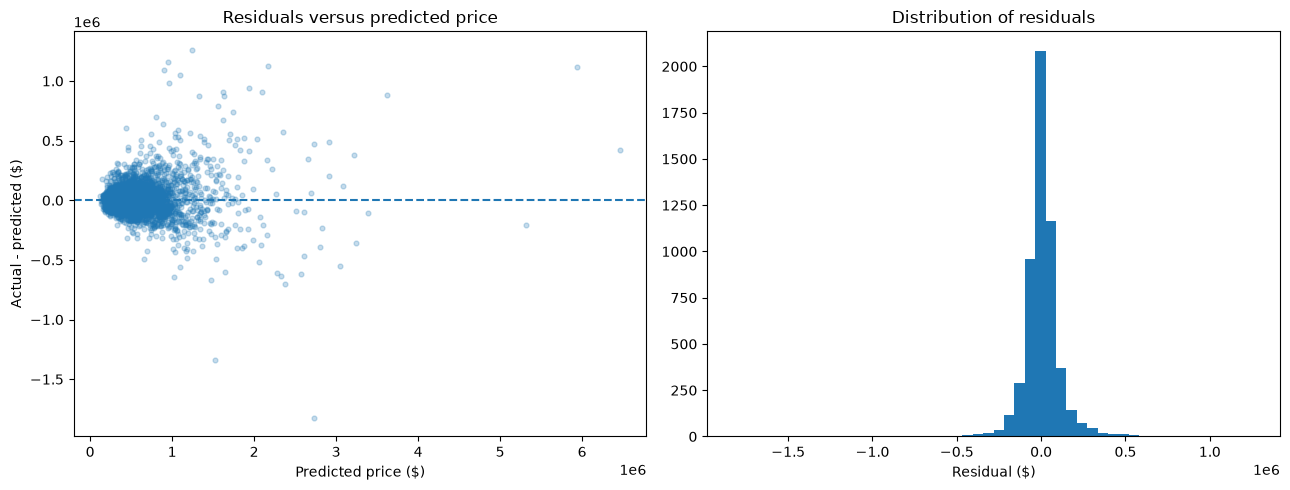

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    best_test_pred,
    residual_df["residual"],
    alpha=0.25,
    s=12
)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted price ($)")
axes[0].set_ylabel("Actual - predicted ($)")
axes[0].set_title("Residuals versus predicted price")

axes[1].hist(residual_df["residual"], bins=50)
axes[1].set_xlabel("Residual ($)")
axes[1].set_title("Distribution of residuals")

plt.tight_layout()
plt.show()

In [23]:
error_columns = [
    "price",
    "predicted_price",
    "residual",
    "absolute_error"
]

for col in [
    "bedrooms",
    "bathrooms",
    "sqft_above",
    "grade",
    "waterfront",
    "zipcode",
    "lat",
    "long"
]:
    if col in residual_df.columns:
        error_columns.append(col)

largest_errors = residual_df.sort_values(
    "absolute_error",
    ascending=False
)[error_columns].head(15)

display(largest_errors)

,price,predicted_price,residual,absolute_error,bedrooms,bathrooms,sqft_above,grade,waterfront,zipcode,lat,long
21034,900000.0,2.725710e+06,-1.825710e+06,1.825710e+06,5.0,6.00,5480.0,12,0.0,98006,47.5451,-122.114
17305,190000.0,1.527139e+06,-1.337139e+06,1.337139e+06,2.0,1.00,710.0,5,0.0,98014,47.6888,-121.909
7304,2500000.0,1.238308e+06,1.261692e+06,1.261692e+06,4.0,4.00,3330.0,10,0.0,98006,47.5708,-122.192
14126,2110000.0,9.479267e+05,1.162073e+06,1.162073e+06,3.0,2.25,3230.0,9,0.0,98006,47.5683,-122.188
18288,3300000.0,2.172256e+06,1.127744e+06,1.127744e+06,5.0,6.25,8020.0,11,0.0,98006,47.5675,-122.189
3910,7060000.0,5.942828e+06,1.117172e+06,1.117172e+06,5.0,4.50,7680.0,11,1.0,98004,47.6500,-122.214
6685,2000000.0,9.055817e+05,1.094418e+06,1.094418e+06,2.0,2.50,3900.0,12,0.0,98065,47.5371,-121.756
4031,2150000.0,1.098127e+06,1.051873e+06,1.051873e+06,8.0,6.00,4340.0,8,0.0,98004,47.6316,-122.202
16238,1950000.0,9.676488e+05,9.823512e+05,9.823512e+05,3.0,2.50,2510.0,10,NaN,98034,47.6982,-122.231
4186,2880000.0,1.935479e+06,9.445210e+05,9.445210e+05,4.0,2.50,4390.0,12,0.0,98177,47.7288,-122.370


# Conclusion

## Final Conclusions: King County House Price Prediction

### 1. Model performance and prediction errors

The residual analysis shows that the model can make substantial errors for individual houses, particularly for expensive properties. Among the 15 largest errors, the absolute prediction errors range from approximately **$879,000 to $1.83 million**.

In contrast, the model underestimated several expensive houses. This suggests that the model struggles to estimate prices accurately for some properties at the higher end of the market.

### 2. Which houses are difficult to predict?

The largest errors occur among houses with a wide range of characteristics, including large living areas, high grades, and multiple bathrooms. Several properties are located in ZIP code 98006, suggesting that location alone does not explain all prediction errors.

The model both overestimates and underestimates expensive houses. Therefore, its errors are not simply caused by consistently predicting prices that are too high or too low. Instead, it appears to have difficulty capturing the specific characteristics that determine the market value of individual properties.

Possible explanations include nonlinear relationships between features and price, differences in property condition, neighborhood-level variation, and the influence of unusual or luxury properties.

### 3. Limitations of the model

Ridge regression is a regularized linear model. Although it can handle correlated predictors and many features, it cannot automatically capture every complex interaction between house characteristics and location.

Polynomial features can capture some nonlinear relationships, but they may still fail to represent complex housing-market patterns. Additional features, more flexible models, or more detailed geographic information could improve predictions.

The log transformation of the target helps reduce the influence of very expensive houses during training. However, converting predictions back to dollars can still result in large absolute errors for expensive properties.

### 4. Overall conclusion

The residual analysis demonstrates that house price prediction is challenging, especially for expensive properties. Although the model captures general relationships between house characteristics and price, its largest errors show that it does not fully capture the variation in the housing market.

The final model should be judged using its cross-validation results and its test-set RMSE, MAE, and R², together with the baseline comparisons. The residuals provide additional insight into where the model performs poorly and which improvements may be worthwhile.